# Digital Image Processing Lab — Lab Task 05: Spatial Filtering and Convolution

**Name:** Afzal Ali Ahmed
**Roll No:** 2024-SE-04
**Department of Software Engineering, University of Azad Jammu and Kashmir** · Fifth Semester, Session 2024-28 (SE)
**Lab Instructor:** Engr. Fahad Nisar · Due: November 20, 2026, 11:59 PM

**Objective.** Implement 2-D convolution from first principles, apply mean, Gaussian and median filters to noisy images, verify hand calculations, and compare against OpenCV.

**Rules followed throughout**

| Rule | Meaning in this notebook |
|---|---|
| R1 | Output has the same size as input; borders use **reflect** padding |
| R2 | Arithmetic in `float64`; convert to `uint8` only at the end with round + clip to 0–255 |
| R3 | Every smoothing kernel sums to 1 |
| R4 | Kernel sizes are odd (3, 5, 7); 3×3 unless stated |
| R5 | All noise uses `seed=5` |
| R6 | Every filtered image is judged against the **clean original**, never the noisy one |

## 1. Setup and test images
`camera`, `coins` and `chelsea` (converted to grayscale) from `skimage.data`. The originals are made read-only so they cannot be changed by accident; a copy is compared at the very end.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import skimage
from skimage import data

plt.rcParams["figure.dpi"] = 90
print("numpy", np.__version__, "| opencv", cv2.__version__, "| skimage", skimage.__version__)

camera  = data.camera()                                    # already grayscale uint8
coins   = data.coins()                                     # already grayscale uint8
chelsea = cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2GRAY) # colour -> grayscale uint8

originals = {"camera": camera, "coins": coins, "chelsea": chelsea}
backup = {k: v.copy() for k, v in originals.items()}       # for the final "unchanged" check
for v in originals.values():
    v.setflags(write=False)                                # originals are now read-only

for k, v in originals.items():
    print(f"{k:8s} shape={v.shape}  dtype={v.dtype}  min={v.min()}  max={v.max()}")

numpy 2.4.6 | opencv 5.0.0 | skimage 0.26.0
camera   shape=(512, 512)  dtype=uint8  min=0  max=255
coins    shape=(303, 384)  dtype=uint8  min=1  max=252
chelsea  shape=(300, 451)  dtype=uint8  min=4  max=194


## 2. `conv2d_loop` — convolution from first principles
Steps for every output pixel `(y, x)`:
1. Convert image and kernel to `float64` (R2).
2. **Flip** the kernel in both directions — this is what makes it *convolution* instead of *correlation*.
3. Pad the image by `k//2` on every side with **reflect** padding (R1).
4. Output pixel = weighted sum of the `kh × kw` window centred on `(y, x)`.

The function returns a `float64` array of the same shape as the input. The `to_uint8` helper (round + clip) is applied only when a final image is needed.

In [2]:
def to_uint8(a):
    """R2: round, clip to 0-255, then convert -- the only place we leave float64."""
    return np.clip(np.rint(a), 0, 255).astype(np.uint8)

def conv2d_loop(img, kernel):
    """True 2-D convolution with nested pixel loops, reflect padding, float64 output."""
    img = np.asarray(img, dtype=np.float64)
    k   = np.asarray(kernel, dtype=np.float64)
    kh, kw = k.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError(f"kernel size must be odd, got {kh}x{kw}")   # R4
    k = k[::-1, ::-1]                                    # flip rows and columns
    ph, pw = kh // 2, kw // 2
    padded = np.pad(img, ((ph, ph), (pw, pw)), mode="reflect")        # R1
    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float64)
    for y in range(H):
        for x in range(W):
            s = 0.0
            for i in range(kh):
                for j in range(kw):
                    s += padded[y + i, x + j] * k[i, j]
            out[y, x] = s
    return out

# Quick proof that the kernel really is flipped: convolving a single bright pixel
# ("impulse") must reproduce the kernel itself, un-flipped.
impulse = np.zeros((5, 5)); impulse[2, 2] = 1
K = np.arange(1, 10).reshape(3, 3)
print("kernel:\n", K)
print("conv2d_loop(impulse, K) centre 3x3 (should equal the kernel):\n", conv2d_loop(impulse, K)[1:4, 1:4])
print("output dtype:", conv2d_loop(impulse, K).dtype, "| same shape as input:", conv2d_loop(impulse, K).shape == impulse.shape)

kernel:
 [[1 2 3]
 [4 5 6]
 [7 8 9]]
conv2d_loop(impulse, K) centre 3x3 (should equal the kernel):
 [[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
output dtype: float64 | same shape as input: True


## 3. Verifying `conv2d_loop` against OpenCV
OpenCV's `cv2.filter2D` actually computes *correlation*, so to compare with true convolution the kernel is flipped for OpenCV (`cv2.flip(K, -1)`). OpenCV's default border `BORDER_REFLECT_101` is the same as NumPy's `mode="reflect"` (the edge pixel is not repeated).

Two checks on the real `camera` image (512 × 512):
* **A.** An *asymmetric* kernel in float64 — this also proves the flip is right.
* **B.** The 3×3 mean filter, rounded to `uint8`, against `cv2.blur`.

In [3]:
# --- A: asymmetric kernel, float64, flip-sensitive -------------------------------------------
K_asym = np.array([[0, 1, 2],
                   [3, 4, 5],
                   [6, 7, 8]], dtype=np.float64)
K_asym /= K_asym.sum()

mine_A = conv2d_loop(camera, K_asym)
cv_A   = cv2.filter2D(camera.astype(np.float64), -1, cv2.flip(K_asym, -1),
                      borderType=cv2.BORDER_REFLECT_101)
print(f"A. asymmetric kernel, float64 : max |mine - OpenCV| = {np.abs(mine_A - cv_A).max():.3e}")

# what happens if we had forgotten to flip (i.e. computed correlation)?
cv_A_unflipped = cv2.filter2D(camera.astype(np.float64), -1, K_asym, borderType=cv2.BORDER_REFLECT_101)
print(f"   (without flipping the kernel the difference would be {np.abs(mine_A - cv_A_unflipped).max():.2f} grey levels)")

# --- B: 3x3 mean, uint8 -----------------------------------------------------------------------
mean3 = np.full((3, 3), 1 / 9)
mine_B = to_uint8(conv2d_loop(camera, mean3))
cv_B   = cv2.blur(camera, (3, 3))
diff_B = np.abs(mine_B.astype(int) - cv_B.astype(int))
print(f"B. 3x3 mean, uint8            : max |mine - cv2.blur| = {diff_B.max()} grey level(s); "
      f"pixels that differ = {np.count_nonzero(diff_B)} of {diff_B.size}")
print("   dtype:", mine_B.dtype, "| shape equal:", mine_B.shape == camera.shape)

A. asymmetric kernel, float64 : max |mine - OpenCV| = 0.000e+00
   (without flipping the kernel the difference would be 104.11 grey levels)
B. 3x3 mean, uint8            : max |mine - cv2.blur| = 0 grey level(s); pixels that differ = 0 of 262144
   dtype: uint8 | shape equal: True


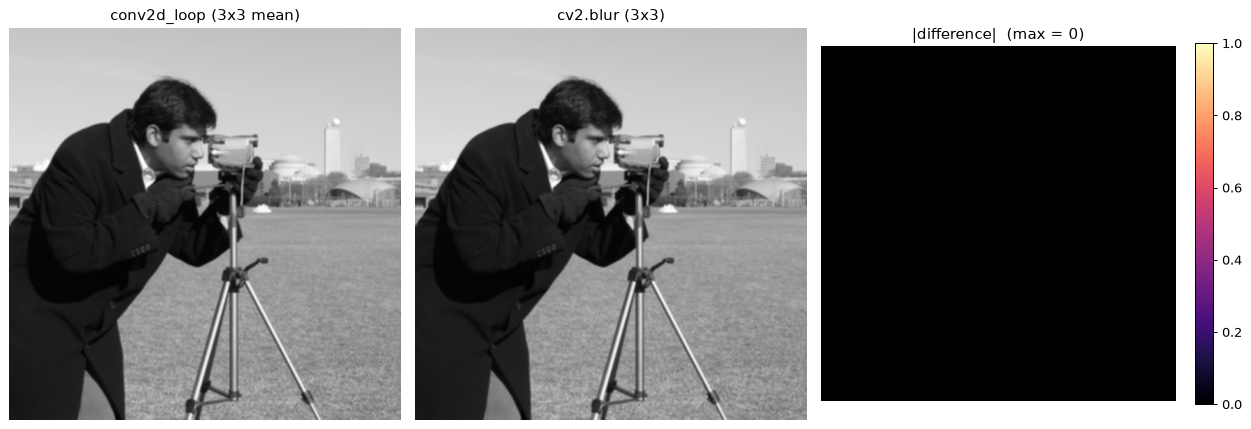

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.8))
ax[0].imshow(mine_B, cmap="gray", vmin=0, vmax=255); ax[0].set_title("conv2d_loop (3x3 mean)")
ax[1].imshow(cv_B,   cmap="gray", vmin=0, vmax=255); ax[1].set_title("cv2.blur (3x3)")
im = ax[2].imshow(diff_B, cmap="magma", vmin=0, vmax=1); ax[2].set_title(f"|difference|  (max = {diff_B.max()})")
for a in ax: a.axis("off")
plt.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout(); plt.show()

## 4. Noise generators (R5)
Both generators build their own `np.random.default_rng(seed)` on every call, so the same seed always gives the same noise.

* **Gaussian noise** — add `N(0, σ²)` noise to every pixel in `float64`, then round and clip (R2).
* **Salt & pepper** — draw one uniform random number per pixel; the lowest `amount/2` become 0 (pepper), the next `amount/2` become 255 (salt).

In [5]:
def add_gaussian_noise(img, sigma=20, seed=5):
    rng = np.random.default_rng(seed)
    noisy = img.astype(np.float64) + rng.normal(loc=0.0, scale=sigma, size=img.shape)
    return to_uint8(noisy)

def add_salt_pepper(img, amount=0.05, seed=5):
    rng = np.random.default_rng(seed)
    r = rng.random(img.shape)
    out = img.copy()
    out[r < amount / 2] = 0                          # pepper
    out[(r >= amount / 2) & (r < amount)] = 255      # salt
    return out

def mse(a, b):
    return np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)

def psnr(clean, test):
    """PSNR in dB of `test` measured against the CLEAN original (R6)."""
    return 10 * np.log10(255.0 ** 2 / mse(clean, test))

noisy = {}
for name, img in originals.items():
    noisy[(name, "gaussian")] = add_gaussian_noise(img, sigma=20, seed=5)
    noisy[(name, "sp")]       = add_salt_pepper(img, amount=0.05, seed=5)

for (name, kind), im in noisy.items():
    print(f"{name:8s} {kind:9s} dtype={im.dtype}  PSNR vs clean = {psnr(originals[name], im):5.2f} dB")

camera   gaussian  dtype=uint8  PSNR vs clean = 22.40 dB
camera   sp        dtype=uint8  PSNR vs clean = 17.68 dB
coins    gaussian  dtype=uint8  PSNR vs clean = 22.20 dB
coins    sp        dtype=uint8  PSNR vs clean = 18.09 dB
chelsea  gaussian  dtype=uint8  PSNR vs clean = 22.12 dB
chelsea  sp        dtype=uint8  PSNR vs clean = 18.66 dB


### 4.1 Reproducibility check (R5)
Everything is regenerated from scratch with `seed=5` and compared to the first set with `np.array_equal`. A different seed is used as a control to show the check can actually fail.

In [6]:
all_equal = True
for name, img in originals.items():
    g2  = add_gaussian_noise(img, sigma=20, seed=5)
    sp2 = add_salt_pepper(img, amount=0.05, seed=5)
    same_g, same_sp = np.array_equal(g2, noisy[(name, "gaussian")]), np.array_equal(sp2, noisy[(name, "sp")])
    all_equal &= same_g and same_sp
    print(f"{name:8s} regenerated gaussian identical: {same_g} | salt&pepper identical: {same_sp}")
print("All regenerated images identical to the first run:", all_equal)

control = add_gaussian_noise(camera, sigma=20, seed=6)
print("Control (seed=6) identical to seed=5 result?      ", np.array_equal(control, noisy[("camera", "gaussian")]))

sp = noisy[("camera", "sp")]
print(f"Salt & pepper check on camera: {np.mean(sp != camera)*100:.2f}% of pixels changed (target ~5%)")

camera   regenerated gaussian identical: True | salt&pepper identical: True
coins    regenerated gaussian identical: True | salt&pepper identical: True
chelsea  regenerated gaussian identical: True | salt&pepper identical: True
All regenerated images identical to the first run: True
Control (seed=6) identical to seed=5 result?       False
Salt & pepper check on camera: 5.02% of pixels changed (target ~5%)


### 4.2 Noise comparison grid — original vs Gaussian vs salt & pepper
Each noisy title shows its PSNR measured against the clean original.

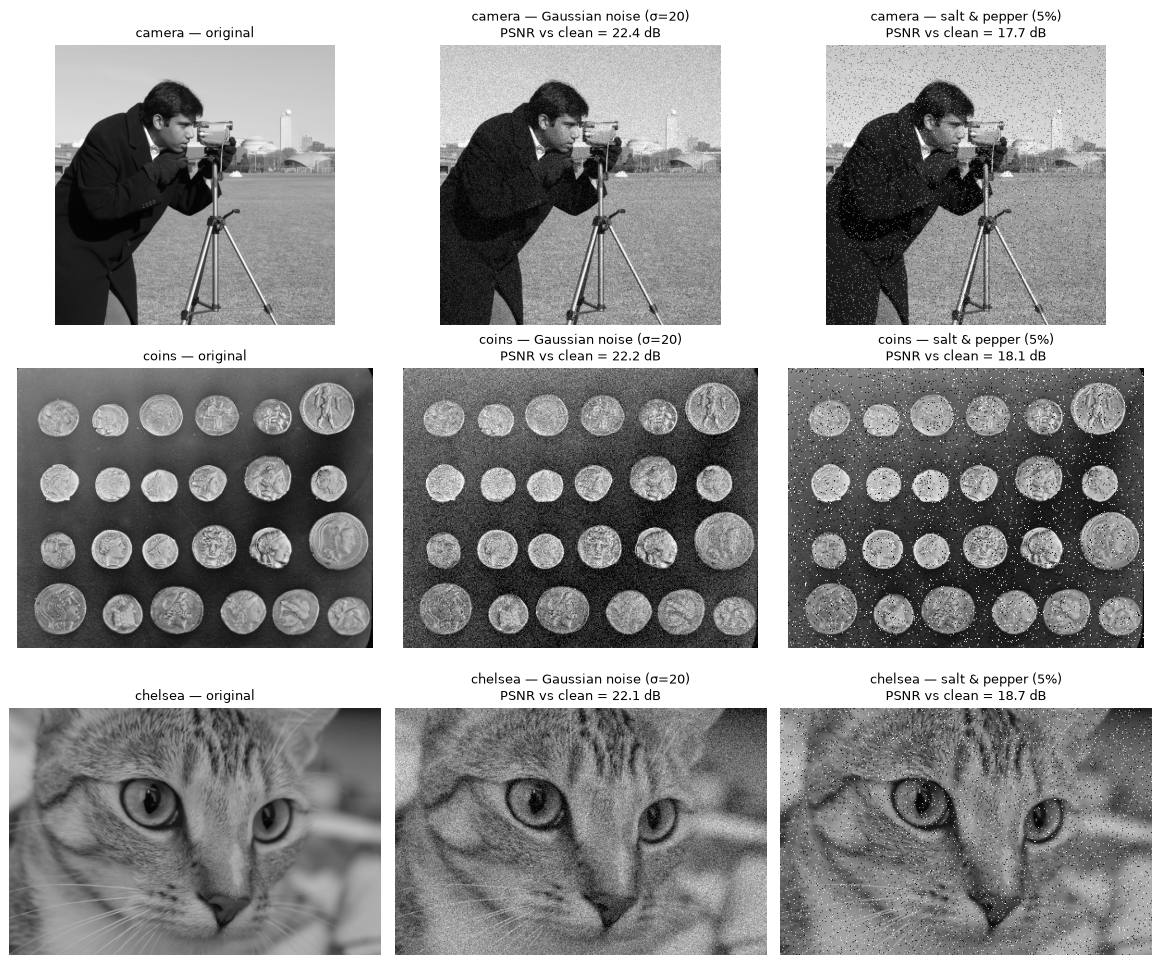

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for r, (name, img) in enumerate(originals.items()):
    panels = [("original", img),
              ("Gaussian noise (σ=20)", noisy[(name, "gaussian")]),
              ("salt & pepper (5%)",    noisy[(name, "sp")])]
    for c, (label, im) in enumerate(panels):
        ax = axes[r, c]
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        extra = f"\nPSNR vs clean = {psnr(img, im):.1f} dB" if c else ""
        ax.set_title(f"{name} — {label}{extra}", fontsize=10)
        ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Smoothing kernels and the weight-sum check (R3)
* **Mean:** every weight is `1/size²`.
* **Gaussian:** `cv2.getGaussianKernel(size, 0)` gives the 1-D weights that `cv2.GaussianBlur(img, (size, size), 0)` uses internally; the 2-D kernel is their outer product. At 3×3 this is exactly the `1-2-1 ÷ 16` kernel.
* **Median** has no weights (it sorts the neighbourhood), so R3 does not apply to it.

Every kernel's weight sum is printed and asserted to be 1 *before* the kernel is used.

In [8]:
def mean_kernel(n):
    return np.full((n, n), 1.0 / (n * n))

def gaussian_kernel(n):
    g = cv2.getGaussianKernel(n, 0)          # column vector, sums to 1
    return g @ g.T                           # outer product -> 2-D kernel

for n in (3, 5, 7):
    for label, K in (("mean", mean_kernel(n)), ("gaussian", gaussian_kernel(n))):
        s = K.sum()
        print(f"{label:8s} {n}x{n}: weight sum = {s:.12f}")
        assert np.isclose(s, 1.0), "R3 violated"
print("\nAll smoothing kernels sum to 1  ->  R3 satisfied")

print("\nGaussian 3x3 x 16 (should be the 1-2-1 kernel):\n", np.rint(gaussian_kernel(3) * 16).astype(int))
print("Gaussian 5x5 x 256:\n", np.rint(gaussian_kernel(5) * 256).astype(int))

mean     3x3: weight sum = 1.000000000000
gaussian 3x3: weight sum = 1.000000000000
mean     5x5: weight sum = 1.000000000000
gaussian 5x5: weight sum = 1.000000000000
mean     7x7: weight sum = 1.000000000000
gaussian 7x7: weight sum = 1.000000000000

All smoothing kernels sum to 1  ->  R3 satisfied

Gaussian 3x3 x 16 (should be the 1-2-1 kernel):
 [[1 2 1]
 [2 4 2]
 [1 2 1]]
Gaussian 5x5 x 256:
 [[ 1  4  6  4  1]
 [ 4 16 24 16  4]
 [ 6 24 36 24  6]
 [ 4 16 24 16  4]
 [ 1  4  6  4  1]]


## 6. The three filters, and rejecting even kernel sizes (R4)
* `mean_filter` → `cv2.blur` (also done once with `conv2d_loop`, see section 7).
* `gaussian_filter` → `cv2.GaussianBlur` (default border = reflect, R1).
* `median_filter` → `cv2.medianBlur`. OpenCV's median replicates edge pixels internally, so to obey R1 the image is first padded with reflect padding (`BORDER_REFLECT_101`) and the result is cropped back to the original size.

A shared `check_size` rejects everything except 3, 5 and 7.

In [9]:
def check_size(n):
    if n % 2 == 0 or n not in (3, 5, 7):
        raise ValueError(f"kernel size must be 3, 5 or 7 (odd), got {n}")   # R4

def mean_filter(img, n=3):
    check_size(n)
    return cv2.blur(img, (n, n))

def gaussian_filter(img, n=3):
    check_size(n)
    return cv2.GaussianBlur(img, (n, n), 0)

def median_filter(img, n=3):
    check_size(n)
    p = n // 2
    padded = cv2.copyMakeBorder(img, p, p, p, p, cv2.BORDER_REFLECT_101)   # reflect padding (R1)
    return cv2.medianBlur(padded, n)[p:-p, p:-p]

FILTERS = {"mean": mean_filter, "gaussian": gaussian_filter, "median": median_filter}
SIZES = (3, 5, 7)

# ---- R4 demonstration: an even kernel size is rejected ----
print("1) OpenCV itself:")
try:
    cv2.medianBlur(camera, 4)
except cv2.error as e:
    print("   cv2.medianBlur(img, 4) raised cv2.error ->", str(e).strip().splitlines()[-1][:110])

print("2) Our wrappers and conv2d_loop:")
for label, call in (("median_filter(img, 4)", lambda: median_filter(camera, 4)),
                    ("mean_filter(img, 6)",   lambda: mean_filter(camera, 6)),
                    ("conv2d_loop(img, 4x4)", lambda: conv2d_loop(camera, np.ones((4, 4)) / 16))):
    try:
        call()
    except ValueError as e:
        print(f"   {label:24s} raised ValueError -> {e}")

1) OpenCV itself:
   cv2.medianBlur(img, 4) raised cv2.error -> OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\median_blur.dispatch.cpp:192: error:
2) Our wrappers and conv2d_loop:
   median_filter(img, 4)    raised ValueError -> kernel size must be 3, 5 or 7 (odd), got 4
   mean_filter(img, 6)      raised ValueError -> kernel size must be 3, 5 or 7 (odd), got 6
   conv2d_loop(img, 4x4)    raised ValueError -> kernel size must be odd, got 4x4


## 7. Apply every filter at 3×3, 5×5 and 7×7 to every noisy image
6 noisy images × 3 filters × 3 sizes = 54 outputs, followed by the R1/R2 compliance check (dtype `uint8`, values 0–255, same shape as the input).

In [10]:
results = {}
for (name, kind), noisy_img in noisy.items():
    for fname, f in FILTERS.items():
        for n in SIZES:
            results[(name, kind, fname, n)] = f(noisy_img, n)

bad = 0
for (name, kind, fname, n), out in results.items():
    ok = (out.dtype == np.uint8) and (out.min() >= 0) and (out.max() <= 255) and (out.shape == originals[name].shape)
    bad += not ok
print(f"Outputs checked: {len(results)}")
print(f"dtype uint8 + range 0-255 + shape == input (R1, R2): {len(results) - bad} OK, {bad} violations")
assert bad == 0

Outputs checked: 54
dtype uint8 + range 0-255 + shape == input (R1, R2): 54 OK, 0 violations


### 7.1 Own loop vs OpenCV for the mean filter
The mean filter is applied once with `conv2d_loop` (all three sizes, on the Gaussian-noisy `coins` image) and compared to the `cv2.blur` result. Differences can only come from rounding.

In [11]:
src = noisy[("coins", "gaussian")]
for n in SIZES:
    mine = to_uint8(conv2d_loop(src, mean_kernel(n)))
    ref  = results[("coins", "gaussian", "mean", n)]
    d = np.abs(mine.astype(int) - ref.astype(int))
    print(f"mean {n}x{n}: max |conv2d_loop - cv2.blur| = {d.max()} grey level(s); "
          f"identical pixels = {np.mean(d == 0)*100:.3f}%")

mean 3x3: max |conv2d_loop - cv2.blur| = 0 grey level(s); identical pixels = 100.000%
mean 5x5: max |conv2d_loop - cv2.blur| = 0 grey level(s); identical pixels = 100.000%
mean 7x7: max |conv2d_loop - cv2.blur| = 0 grey level(s); identical pixels = 100.000%


## 8. Dry-run exercises (hand calculations next to the matching code)

### Exercise 1 — Spike response
Neighbourhood centred on one bright pixel:

$$\begin{bmatrix}40&40&40\\40&255&40\\40&40&40\end{bmatrix}$$

**3×3 mean kernel** (all weights 1/9)
* sum of the 8 neighbours = 8 × 40 = 320
* total = 320 + 255 = 575
* centre output = 575 / 9 = **63.89 → 64**

**3×3 Gaussian kernel** $\frac{1}{16}\begin{bmatrix}1&2&1\\2&4&2\\1&2&1\end{bmatrix}$
* corners: (1+1+1+1) × 40 = 160
* edges: (2+2+2+2) × 40 = 320
* centre: 4 × 255 = 1020
* total = 160 + 320 + 1020 = 1500
* centre output = 1500 / 16 = 93.75 → **94**

**3×3 median**
* sorted values: 40, 40, 40, 40, 40, 40, 40, 40, 255
* the middle (5th of 9) value is **40** — the spike is completely removed.

In [12]:
win = np.array([[40, 40, 40],
                [40, 255, 40],
                [40, 40, 40]], dtype=np.float64)

mean_k, gauss_k = mean_kernel(3), np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16.0
print("kernel weight sums:", mean_k.sum(), gauss_k.sum())

mean_val  = (win * mean_k).sum()
gauss_val = (win * gauss_k).sum()
med_val   = np.median(win)
print(f"mean     : 8*40 + 255 = {8*40 + 255} ; {8*40 + 255}/9  = {mean_val:.4f} -> {int(to_uint8(mean_val))}")
print(f"gaussian : 160 + 320 + 1020 = {160 + 320 + 1020} ; 1500/16 = {gauss_val:.4f} -> {int(to_uint8(gauss_val))}")
print(f"median   : sorted = {sorted(win.ravel().astype(int).tolist())} -> middle value = {med_val:.0f}")

# cross-check with the real functions: centre pixel of a 3x3 image is the same neighbourhood
w8 = win.astype(np.uint8)
print("\nCross-check with the notebook's own functions (centre pixel):")
print("  conv2d_loop mean     :", conv2d_loop(w8, mean_k)[1, 1])
print("  cv2.blur             :", mean_filter(w8, 3)[1, 1])
print("  conv2d_loop gaussian :", conv2d_loop(w8, gauss_k)[1, 1])
print("  cv2.GaussianBlur     :", gaussian_filter(w8, 3)[1, 1])
print("  cv2.medianBlur       :", median_filter(w8, 3)[1, 1])
assert (int(to_uint8(mean_val)), int(to_uint8(gauss_val)), int(med_val)) == (64, 94, 40)
assert (mean_filter(w8, 3)[1, 1], gaussian_filter(w8, 3)[1, 1], median_filter(w8, 3)[1, 1]) == (64, 94, 40)

kernel weight sums: 1.0 1.0
mean     : 8*40 + 255 = 575 ; 575/9  = 63.8889 -> 64
gaussian : 160 + 320 + 1020 = 1500 ; 1500/16 = 93.7500 -> 94
median   : sorted = [40, 40, 40, 40, 40, 40, 40, 40, 255] -> middle value = 40

Cross-check with the notebook's own functions (centre pixel):
  conv2d_loop mean     : 63.888888888888886
  cv2.blur             : 64
  conv2d_loop gaussian : 93.75
  cv2.GaussianBlur     : 94
  cv2.medianBlur       : 40


### Exercise 2 — Reflect padding at a corner
Image:

$$\begin{bmatrix}10&20&30\\40&50&60\\70&80&90\end{bmatrix}$$

For pixel (0, 0) with `mode="reflect"`, the missing row −1 is a mirror of row 1 and the missing column −1 is a mirror of column 1 (the edge row/column itself is *not* repeated). The 3×3 neighbourhood that gets averaged is:

$$\begin{bmatrix}50&40&50\\20&10&20\\50&40&50\end{bmatrix}$$

(row −1 = row 1 = `[40 50 60]` → mirrored in x → `[50 40 50]`; row 0 = `[10 20 30]` → `[20 10 20]`; row 1 → `[50 40 50]`)

* sum = (50 + 40 + 50) + (20 + 10 + 20) + (50 + 40 + 50) = 140 + 50 + 140 = 330
* mean = 330 / 9 = 36.67 → **37**

In [13]:
img3 = np.array([[10, 20, 30],
                 [40, 50, 60],
                 [70, 80, 90]], dtype=np.float64)

padded = np.pad(img3, 1, mode="reflect")
print("padded image (reflect):\n", padded.astype(int))
nb = padded[0:3, 0:3]                       # neighbourhood of pixel (0, 0)
print("\nneighbourhood averaged at (0,0):\n", nb.astype(int))
print(f"sum = {nb.sum():.0f}, mean = {nb.sum()}/9 = {nb.sum()/9:.4f} -> {int(to_uint8(nb.sum()/9))}")

i3 = img3.astype(np.uint8)
print("\nconv2d_loop mean (0,0):", conv2d_loop(i3, mean_kernel(3))[0, 0])
print("cv2.blur         (0,0):", mean_filter(i3, 3)[0, 0])
assert np.isclose(nb.sum() / 9, 330 / 9) and mean_filter(i3, 3)[0, 0] == 37

padded image (reflect):
 [[50 40 50 60 50]
 [20 10 20 30 20]
 [50 40 50 60 50]
 [80 70 80 90 80]
 [50 40 50 60 50]]

neighbourhood averaged at (0,0):
 [[50 40 50]
 [20 10 20]
 [50 40 50]]
sum = 330, mean = 330.0/9 = 36.6667 -> 37

conv2d_loop mean (0,0): 36.666666666666664
cv2.blur         (0,0): 37


## 9. Filter-comparison grids (3×3 filters on every noisy image)
Column 1 is the noisy input; columns 2–4 are mean, Gaussian and median 3×3. Every title shows the PSNR against the **clean original** (R6) — higher is better.

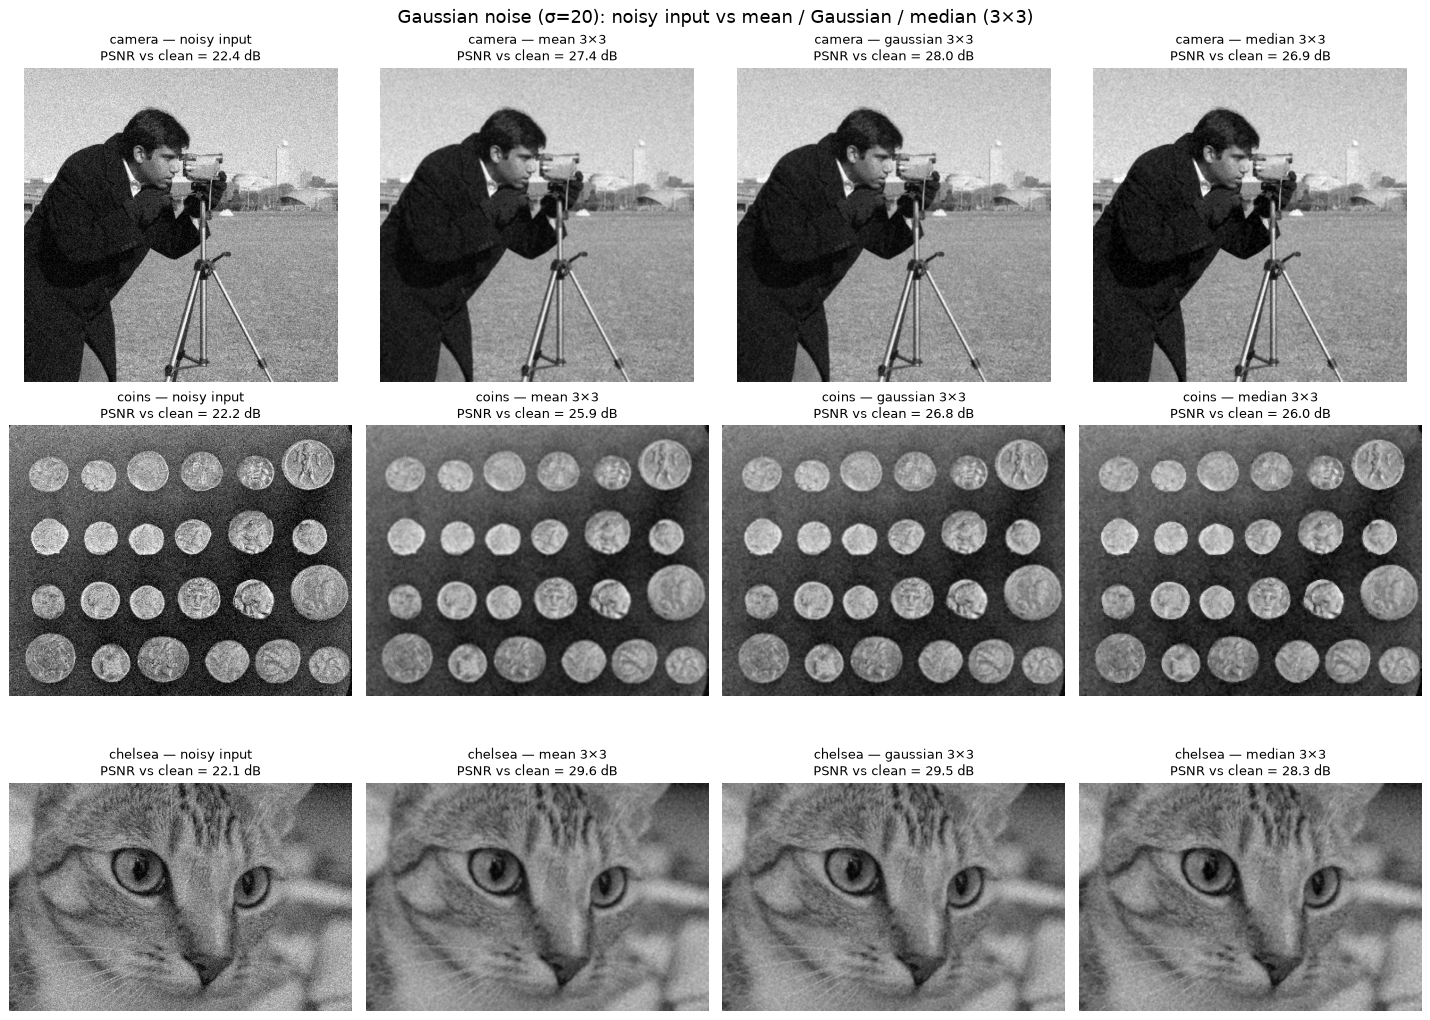

In [14]:
def filter_grid(kind, label):
    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    for r, name in enumerate(originals):
        clean = originals[name]
        panels = [(f"noisy input", noisy[(name, kind)])]
        panels += [(f"{f} 3×3", results[(name, kind, f, 3)]) for f in FILTERS]
        for c, (t, im) in enumerate(panels):
            ax = axes[r, c]
            ax.imshow(im, cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"{name} — {t}\nPSNR vs clean = {psnr(clean, im):.1f} dB", fontsize=10)
            ax.axis("off")
    fig.suptitle(f"{label}: noisy input vs mean / Gaussian / median (3×3)", fontsize=14)
    plt.tight_layout(); plt.show()

filter_grid("gaussian", "Gaussian noise (σ=20)")

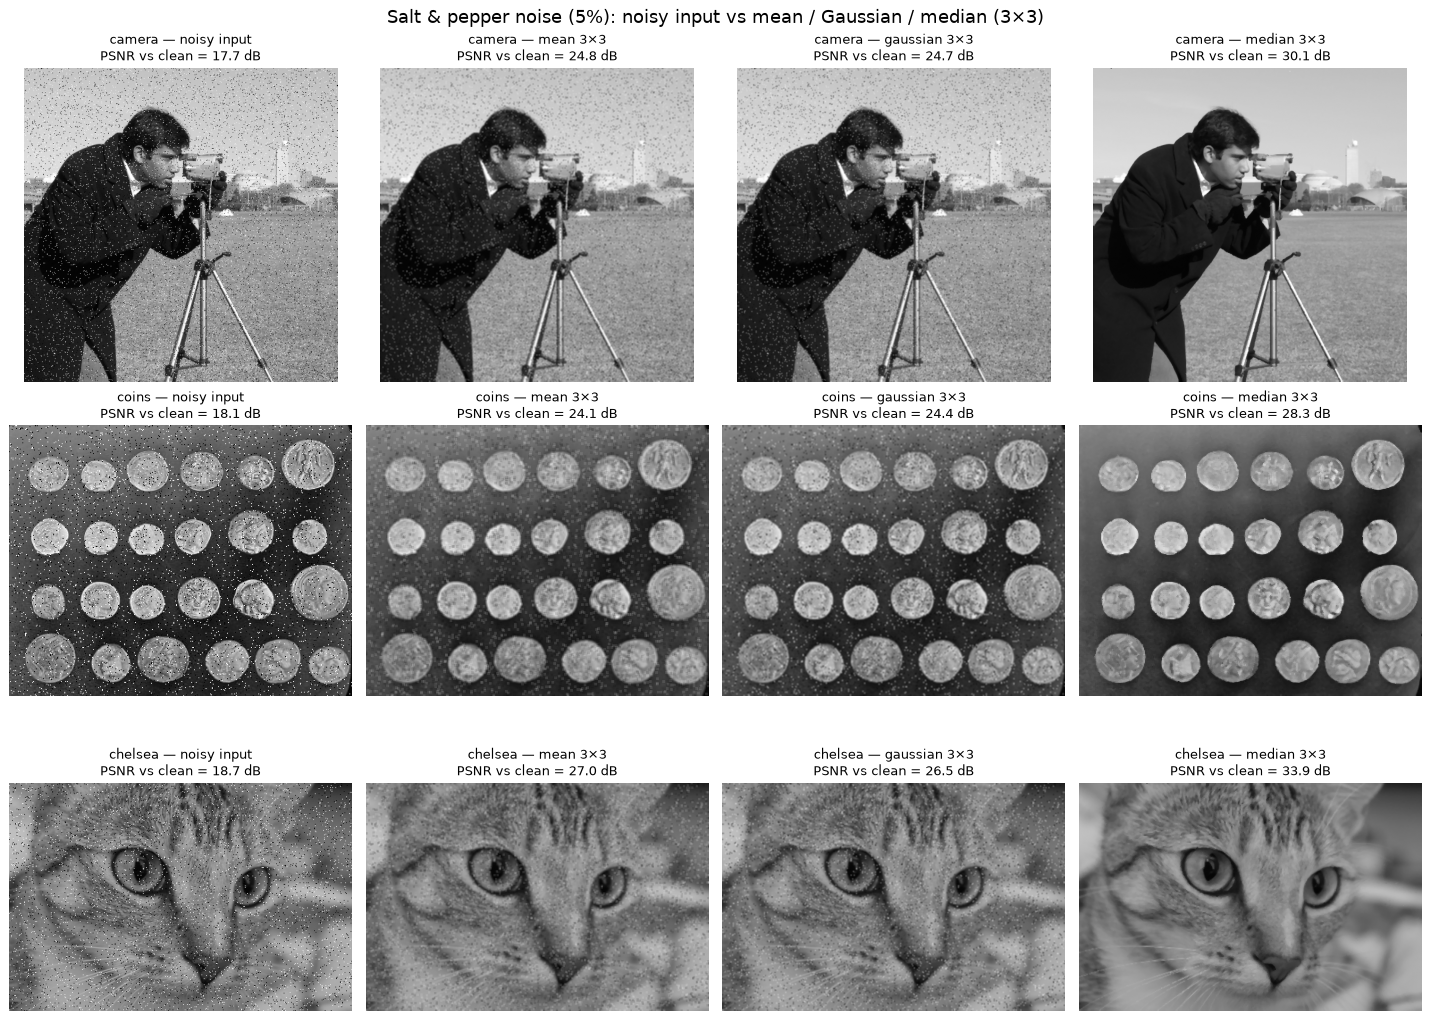

In [15]:
filter_grid("sp", "Salt & pepper noise (5%)")

## 10. Kernel-size grid (filter × kernel size) on the noisiest image
"Noisiest" is decided objectively: the noisy image with the lowest PSNR against its clean original.

PSNR of each noisy image vs its clean original:
  camera   sp        17.68 dB
  coins    sp        18.09 dB
  chelsea  sp        18.66 dB
  chelsea  gaussian  22.12 dB
  coins    gaussian  22.20 dB
  camera   gaussian  22.40 dB

Noisiest image -> ('camera', 'sp')


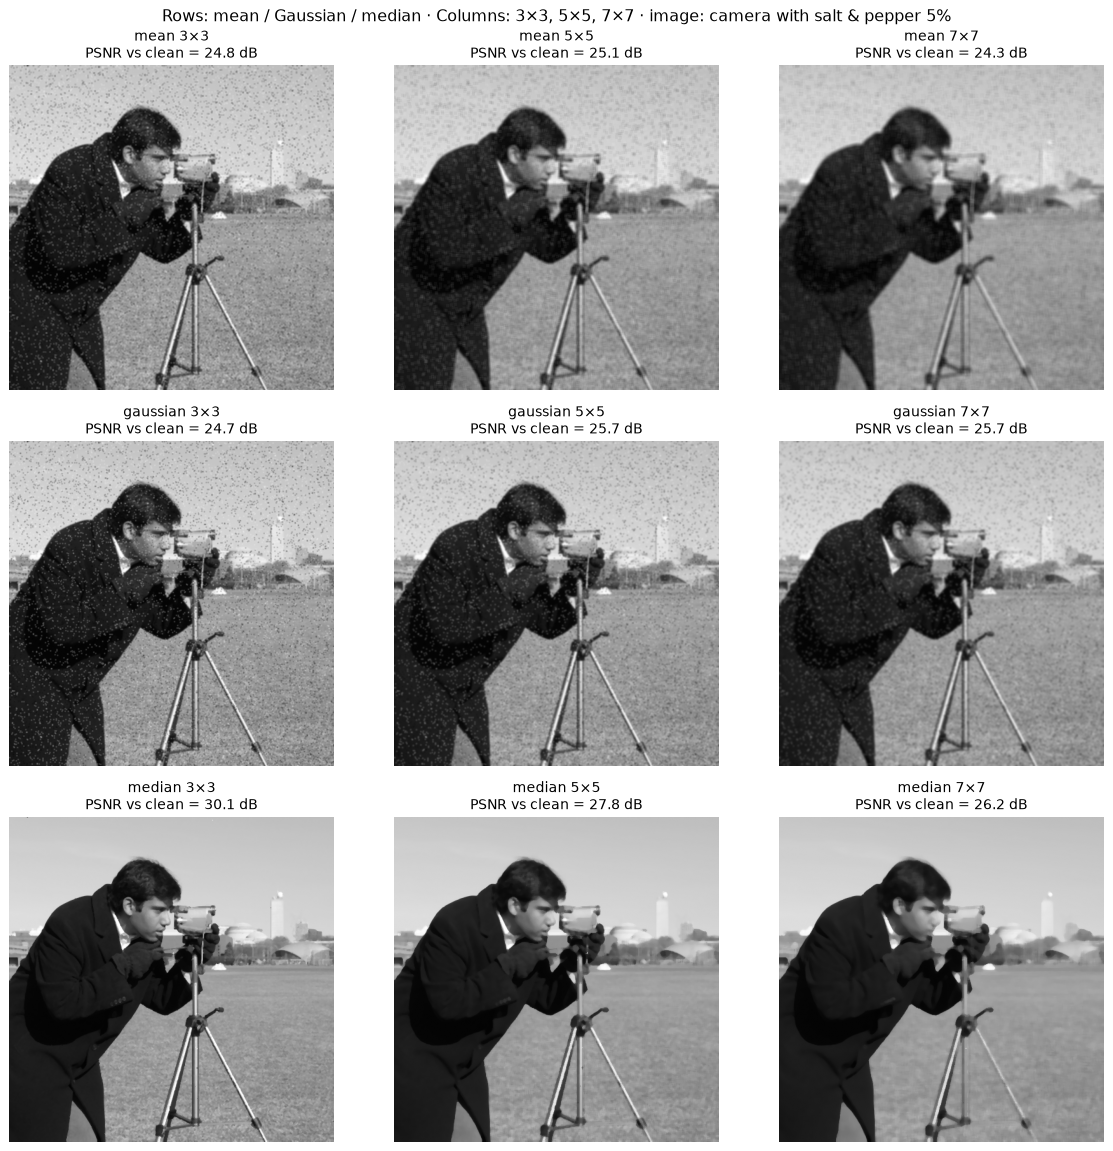

In [16]:
worst_key = min(noisy, key=lambda k: psnr(originals[k[0]], noisy[k]))
w_name, w_kind = worst_key
print("PSNR of each noisy image vs its clean original:")
for k in sorted(noisy, key=lambda k: psnr(originals[k[0]], noisy[k])):
    print(f"  {k[0]:8s} {k[1]:9s} {psnr(originals[k[0]], noisy[k]):5.2f} dB")
print("\nNoisiest image ->", worst_key)

kind_label = {"gaussian": "Gaussian noise σ=20", "sp": "salt & pepper 5%"}[w_kind]
fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for r, fname in enumerate(FILTERS):
    for c, n in enumerate(SIZES):
        im = results[(w_name, w_kind, fname, n)]
        ax = axes[r, c]
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{fname} {n}×{n}\nPSNR vs clean = {psnr(originals[w_name], im):.1f} dB", fontsize=11)
        ax.axis("off")
fig.suptitle(f"Rows: mean / Gaussian / median · Columns: 3×3, 5×5, 7×7 · image: {w_name} with {kind_label}", fontsize=13)
plt.tight_layout(); plt.show()

## 11. Quantitative comparison against the clean original (R6)
PSNR (dB) of every result measured against the **clean** image. Higher is better; the first row of each block is the noisy input.

In [17]:
print(f"{'image / noise':22s}{'noisy':>8s} |" + "".join(f"{f[:4]+' '+str(n):>10s}" for n in SIZES for f in FILTERS))
print("-" * 112)
for (name, kind), nimg in noisy.items():
    row = f"{name + ' / ' + kind:22s}{psnr(originals[name], nimg):8.2f} |"
    for n in SIZES:
        for f in FILTERS:
            row += f"{psnr(originals[name], results[(name, kind, f, n)]):10.2f}"
    print(row)

print("\nBest filter at 3x3 for each case (by PSNR vs clean):")
for (name, kind) in noisy:
    scores = {f: psnr(originals[name], results[(name, kind, f, 3)]) for f in FILTERS}
    best, worst = max(scores, key=scores.get), min(scores, key=scores.get)
    print(f"  {name:8s} {kind:9s} best = {best:8s} ({scores[best]:.2f} dB)   worst = {worst:8s} ({scores[worst]:.2f} dB)")

print("\nAverage PSNR vs clean over the three images (3x3 filters):")
for kind in ("gaussian", "sp"):
    avg = {f: np.mean([psnr(originals[n], results[(n, kind, f, 3)]) for n in originals]) for f in FILTERS}
    noisy_avg = np.mean([psnr(originals[n], noisy[(n, kind)]) for n in originals])
    print(f"  {kind:9s} noisy = {noisy_avg:.2f} | " + " | ".join(f"{f} = {v:.2f}" for f, v in avg.items()))

image / noise            noisy |    mean 3    gaus 3    medi 3    mean 5    gaus 5    medi 5    mean 7    gaus 7    medi 7
----------------------------------------------------------------------------------------------------------------
camera / gaussian        22.40 |     27.37     27.99     26.93     26.17     27.81     26.83     24.85     26.95     25.79
camera / sp              17.68 |     24.84     24.73     30.08     25.09     25.66     27.85     24.26     25.67     26.24
coins / gaussian         22.20 |     25.86     26.79     25.98     24.03     26.02     25.34     22.78     24.87     24.48
coins / sp               18.09 |     24.09     24.37     28.33     23.36     24.58     26.25     22.38     24.04     25.17
chelsea / gaussian       22.12 |     29.55     29.46     28.28     29.56     30.37     29.09     28.75     30.29     28.74
chelsea / sp             18.66 |     26.99     26.51     33.90     28.27     28.10     30.96     27.99     28.78     29.67

Best filter at 3x3 for ea

## 12. Extra evidence for the observations
**(a) A sharp edge** — a one-pixel row profile across a strong, flat-sided edge of the *clean* `camera` image, passed through mean and Gaussian filters, so the edge behaviour is isolated from the noise.
**(b) Fine detail at 7×7** — a zoomed crop of the Gaussian-noisy `camera` image.

edge at row 176, between x=54 and x=55: left plateau = 253, right plateau = 14
10%-90% transition width (pixels): original = 2.36
   3x3: mean = 3.36 px, gaussian = 3.10 px
   5x5: mean = 4.95 px, gaussian = 3.95 px
   7x7: mean = 6.69 px, gaussian = 4.78 px


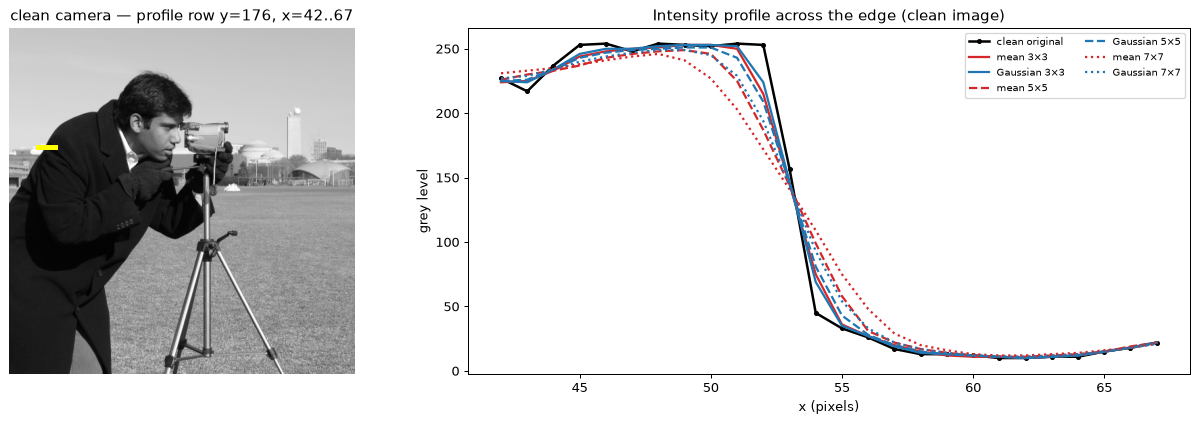

In [18]:
# --- (a) edge profile ------------------------------------------------------------------------
# Search the clean camera image for the cleanest sharp step: flat on both sides, big jump between.
c = camera.astype(np.float64)
best = (0, None, None)
for x in range(8, c.shape[1] - 9):
    L, R = c[:, x - 5:x - 1], c[:, x + 3:x + 7]            # flat plateaus left / right of the edge x|x+1
    ok = (L.std(axis=1) < 2) & (R.std(axis=1) < 2)
    jump = np.where(ok, np.abs(R.mean(axis=1) - L.mean(axis=1)), 0)
    y = int(jump.argmax())
    if jump[y] > best[0]:
        best = (jump[y], y, x)
_, ey, ex = best
lo, hi = c[ey, ex - 5:ex - 1].mean(), c[ey, ex + 3:ex + 7].mean()
xs = np.arange(ex - 12, ex + 14)

def prof(im): return im[ey, xs].astype(float)

def transition_width(p):
    """10%-90% rise distance in pixels, with linear interpolation between samples"""
    t = (p - lo) / (hi - lo)                 # 0 on the left plateau, 1 on the right plateau
    def cross(level):
        j0 = int(np.where(xs == ex - 5)[0][0])            # start just inside the left plateau
        i = j0 + int(np.argmax(t[j0:] >= level))          # first sample at or above the level
        return xs[i - 1] + (level - t[i - 1]) / (t[i] - t[i - 1])
    return cross(0.9) - cross(0.1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].imshow(camera, cmap="gray"); ax[0].plot([xs[0], xs[-1]], [ey, ey], color="yellow", lw=4)
ax[0].set_title(f"clean camera — profile row y={ey}, x={xs[0]}..{xs[-1]}"); ax[0].axis("off")

ax[1].plot(xs, prof(camera), "k-o", ms=3, lw=2, label="clean original")
styles = {3: "-", 5: "--", 7: ":"}
print(f"edge at row {ey}, between x={ex} and x={ex+1}: left plateau = {lo:.0f}, right plateau = {hi:.0f}")
print(f"10%-90% transition width (pixels): original = {transition_width(prof(camera)):.2f}")
for n in (3, 5, 7):
    pm, pg = prof(mean_filter(camera, n)), prof(gaussian_filter(camera, n))
    ax[1].plot(xs, pm, "tab:red",  ls=styles[n], lw=1.8, label=f"mean {n}×{n}")
    ax[1].plot(xs, pg, "tab:blue", ls=styles[n], lw=1.8, label=f"Gaussian {n}×{n}")
    print(f"   {n}x{n}: mean = {transition_width(pm):.2f} px, gaussian = {transition_width(pg):.2f} px")
ax[1].set_xlabel("x (pixels)"); ax[1].set_ylabel("grey level"); ax[1].legend(ncol=2, fontsize=8)
ax[1].set_title("Intensity profile across the edge (clean image)")
plt.tight_layout(); plt.show()

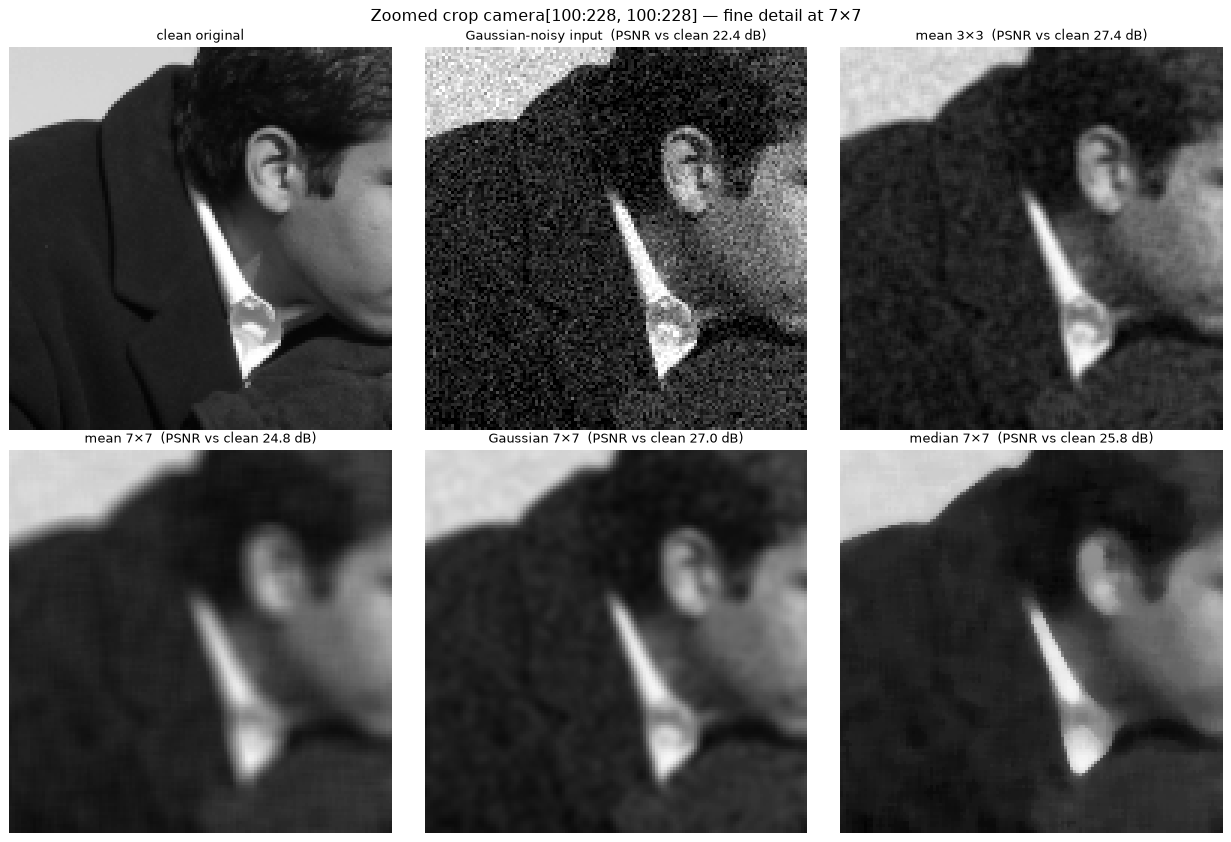

In [19]:
# --- (b) fine detail crop ---------------------------------------------------------------------
y0, y1, x0, x1 = 100, 228, 100, 228
g_noisy = noisy[("camera", "gaussian")]
panels = [("clean original", camera),
          ("Gaussian-noisy input", g_noisy),
          ("mean 3×3", results[("camera", "gaussian", "mean", 3)]),
          ("mean 7×7", results[("camera", "gaussian", "mean", 7)]),
          ("Gaussian 7×7", results[("camera", "gaussian", "gaussian", 7)]),
          ("median 7×7", results[("camera", "gaussian", "median", 7)])]
fig, axes = plt.subplots(2, 3, figsize=(14, 9.5))
for ax, (t, im) in zip(axes.ravel(), panels):
    ax.imshow(im[y0:y1, x0:x1], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    extra = "" if im is camera else f"  (PSNR vs clean {psnr(camera, im):.1f} dB)"
    ax.set_title(t + extra, fontsize=10); ax.axis("off")
fig.suptitle(f"Zoomed crop camera[{y0}:{y1}, {x0}:{x1}] — fine detail at 7×7", fontsize=13)
plt.tight_layout(); plt.show()

**(c) A flat region** — the sky patch `camera[10:60, 10:110]` (top-left of the camera images). Because it is flat in the clean image, any leftover variation is residual noise. The table reports the standard deviation inside the patch (Gaussian noise) and the number of pixels still more than 50 grey levels away from the clean value (salt & pepper).

In [20]:
ys, xs_ = slice(10, 60), slice(10, 110)
clean_patch = camera[ys, xs_].astype(int)
print(f"clean patch: mean = {clean_patch.mean():.1f}, std = {clean_patch.std():.2f}\n")

print("Gaussian noise — std of the patch (lower = smoother):")
print(f"  noisy input : {noisy[('camera', 'gaussian')][ys, xs_].std():6.2f}")
for f in FILTERS:
    print(f"  {f:8s} 3x3 : {results[('camera', 'gaussian', f, 3)][ys, xs_].std():6.2f}")

print("\nSalt & pepper — pixels in the patch still > 50 levels from the clean value "
      f"(patch has {clean_patch.size} pixels):")
print(f"  noisy input : {np.sum(np.abs(noisy[('camera', 'sp')][ys, xs_].astype(int) - clean_patch) > 50):5d}")
for f in FILTERS:
    out = results[('camera', 'sp', f, 3)][ys, xs_].astype(int)
    print(f"  {f:8s} 3x3 : {np.sum(np.abs(out - clean_patch) > 50):5d}")

clean patch: mean = 203.5, std = 3.10

Gaussian noise — std of the patch (lower = smoother):
  noisy input :  20.12
  mean     3x3 :   7.16
  gaussian 3x3 :   7.91
  median   3x3 :   8.48

Salt & pepper — pixels in the patch still > 50 levels from the clean value (patch has 5000 pixels):
  noisy input :   173
  mean     3x3 :     4
  gaussian 3x3 :    73
  median   3x3 :     0


## 13. Observations (answered from this notebook's own figures, judged against the clean original — R6)
All PSNR values below are measured against the **clean original** (R6) and come from the printed table in section 11 and the figures above.

**Q1. Which filter looks best on Gaussian noise, and which looks worst?**  
**Best: the Gaussian filter. Worst: the median filter.** In the 3×3 Gaussian-noise grid (section 9), averaged over the three images, the Gaussian filter reaches 28.08 dB against 27.59 dB for mean and 27.07 dB for median (the noisy inputs average 22.24 dB). On `camera` it is 27.99 dB (Gaussian) vs 27.37 dB (mean) vs 26.93 dB (median), and on `coins` it is 26.79 dB vs 25.86 dB vs 25.98 dB. The one exception is `chelsea`, where mean edges it out by 0.09 dB (29.55 vs 29.46), which is effectively a tie. The flat-sky patch `camera[10:60, 10:110]` (section 12c) shows the reason: its std is 20.1 in the noisy input, 7.2 after mean, 7.9 after Gaussian and 8.5 after median. The median filter removes the least Gaussian noise because every output is just one of the noisy neighbours, so the noise is never averaged out. The mean filter smooths the sky slightly more than the Gaussian filter but pays for it at edges (see Q3).

**Q2. Which filter looks best on salt-and-pepper noise, and why do the other two fail?**  
**The median filter is clearly best.** It scores 30.08 dB on `camera`, 28.33 dB on `coins` and 33.90 dB on `chelsea`, while mean and Gaussian score only 24–27 dB (averages 30.77 dB vs 25.31 dB and 25.20 dB). In the `camera` salt-and-pepper grid, the sky patch at the top-left is spotless in the median panel (0 pixels left more than 50 levels from the clean value, section 12c), whereas the mean and Gaussian panels still show grey blotches where each black or white dot was smeared into its 3×3 neighbourhood (Gaussian: 73 pixels still wrong by more than 50 levels). They fail because they are *linear*: the spike is not removed, it is averaged into its neighbours. Dry-run exercise 1 shows this numerically: a 255 spike among 40s becomes 64 after the mean filter and 94 after the Gaussian filter (which weights the centre pixel 4/16), but 40 after the median, because the spike sorts to the end of the list and the middle value ignores it.

**Q3. How do mean and Gaussian compare on a sharp edge?**  
In the edge profile of section 12a (clean `camera`, row 176, x = 42…67, the sky-to-coat edge at the left of the image, 253 → 14) the original rises from 10% to 90% in 2.36 px. The mean filter widens this to 3.36 / 4.95 / 6.69 px at 3×3 / 5×5 / 7×7, while the Gaussian filter gives 3.10 / 3.95 / 4.78 px. In the plot the red dotted mean 7×7 curve starts to sag several pixels before the edge, and its slope is clearly gentler than that of the blue dotted Gaussian 7×7 curve. The mean treats all pixels in the window equally, so a far-away dark pixel pulls the result down as much as a near one. The Gaussian weights the centre most (4/16 vs 1/9 at 3×3), so it keeps more of the edge. The gap grows with kernel size.

**Q4. What happens to fine detail at 7×7?**  
It is largely lost. In the zoomed crop `camera[100:228, 100:228]` (section 12b) the folds inside the ear and the small bright glint on the collar are visible after 3×3 filtering, but at 7×7 they merge into smooth blobs, with mean 7×7 the softest. Over-smoothing even hurts the score: on Gaussian-noisy `camera`, mean falls from 27.37 dB (3×3) to 24.85 dB (7×7), Gaussian from 27.99 to 26.95 dB and median from 26.93 to 25.79 dB. In the kernel-size grid on the noisiest image (`camera` with salt and pepper, section 10) the median drops from 30.08 dB at 3×3 to 26.24 dB at 7×7, and the skyline buildings and tripod legs lose crispness and look "painted", while mean and Gaussian at 7×7 still show the dark specks as larger, blurrier smudges. A bigger kernel removes more noise but destroys detail of the same size, so 3×3 is the best compromise here.

**Q5. Why must the kernel size be odd?**  
Only an odd kernel has a single centre pixel with the same number of neighbours on each side (`k // 2`), so the output sits exactly on the input pixel and the padding `k // 2` is symmetric. An even kernel (e.g. 4×4) has no centre, so the result would be shifted by half a pixel, and for the median there would be an even count of values (16) with no single middle element. The notebook shows this in section 6: `cv2.medianBlur(img, 4)` raises `cv2.error` (assertion failed), and our own wrappers and `conv2d_loop` raise `ValueError` for 4, 6 and 4×4.

## 14. Viva preparation
**1. What is a kernel?**  
A small matrix of weights (3×3, 5×5, 7×7) that is slid over the image. At each position the output pixel is the weighted sum of the neighbourhood under it. For smoothing kernels the weights sum to 1 (R3), e.g. all `1/9` for the 3×3 mean.

**2. Apply a 3×3 mean kernel to a 3×3 window given on the spot.**  
Add all nine values and divide by 9, then round. Example from Exercise 1: `(8×40 + 255) / 9 = 575 / 9 = 63.89 → 64`.

**3. Why does the median remove a 255 spike but the mean does not?**  
The median sorts the window and takes the middle value; a spike always ends up at the very end of the sorted list, so it is never picked (Exercise 1: sorted `40,…,40,255` → median 40). The mean uses every value, so the spike contributes 255/9 ≈ 28 to the sum and pulls the result up to 64.

**4. Why do the Gaussian weights sum to 16, and why divide by it?**  
`1+2+1+2+4+2+1+2+1 = 16`. The integer weights `[1 2 1; 2 4 2; 1 2 1]` are easy to calculate by hand, and dividing by 16 makes the weights sum to 1 (R3) so flat regions keep their brightness: an all-100 window gives 1600 / 16 = 100.

**5. Why do we pad the border before filtering?**  
Border pixels do not have a full neighbourhood. Without padding the output would be smaller than the input (breaking R1), or the edge would need special handling. Reflect padding mirrors the pixels inside the image so the output keeps the same size and the border brightness is not distorted (Exercise 2: the corner (0,0) uses the neighbourhood `[[50,40,50],[20,10,20],[50,40,50]]` and gives 37).

**6. Which filter would you use for salt-and-pepper noise, and why?**  
The median filter. The noisy pixels are extreme outliers (0 or 255); the median discards them instead of averaging them into the neighbours, and it keeps edges sharper than mean or Gaussian (30.77 dB average vs about 25 dB at 3×3 in section 11).

## 15. Final integrity checks

In [21]:
print("Originals unchanged:", all(np.array_equal(originals[k], backup[k]) for k in originals))
print("Originals still read-only:", all(not v.flags.writeable for v in originals.values()))
print("Total filtered outputs:", len(results), "| all uint8:", all(v.dtype == np.uint8 for v in results.values()))

Originals unchanged: True
Originals still read-only: True
Total filtered outputs: 54 | all uint8: True
